# Replicating Hodgkin-Huxley Spiking Dynamics with Rudimentary Universal Function Approximators: A Comparative Study

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("No GPU detected -- Runtime > Change runtime type > GPU is recommended for the full-scale run.")

Using device: cuda


## 1. Introduction

The **Hodgkin-Huxley (HH) model** (Hodgkin & Huxley, 1952) describes how a
neuron's membrane voltage changes over time as a function of injected
current and the opening/closing of specific ion channels. It remains the
standard reference model of single-neuron electrical activity. Critically,
the model's equations depend not only on the observable quantities -
injected current ($I$) and voltage ($V$) - but also on three **hidden
variables** describing channel state, which are not directly observable
from $I$ and $V$ alone.

A long-running question in computational neuroscience and systems
identification is whether a model can be fit to *input-output data alone*
(without the modeler supplying the hidden biophysical variables by hand) and
still reproduce a system's true dynamics. Two broad traditions address this:

**Classical system identification.** Long before modern machine learning,
techniques such as **Volterra-Wiener kernel methods** were developed to fit
general nonlinear input-output models of physiological systems directly
from stimulus-response data, without assuming a specific mechanistic form
(Marmarelis & Marmarelis, 1978). These methods have been applied directly to
real neurons - for example, to characterize how auditory-cortex neurons
transform sound-driven input into spiking output. A simpler, widely used
relative of this approach is the **linear ARX model** ("AutoRegressive with
eXogenous input"), which predicts a system's next state from a short window
of its own recent past plus recent inputs, fit by ordinary linear
regression.

**Modern neural-network approaches.** More recently, researchers have asked
whether trainable neural networks can reproduce Hodgkin-Huxley-type
dynamics without being given the gating-variable equations at all. Kuptsov,
Stankevich, and Bagautdinova (2022) trained feedforward networks, used as
step-by-step "recurrent maps," to reproduce the dynamics of Hodgkin-Huxley
type models purely from example trajectories. Other recent work has used
**neural ODEs** (models that learn a differential equation rather than a
fixed-step mapping) to recover the dynamics of a *specific* HH gating
variable from voltage recordings alone, with that variable deliberately
withheld from training (Kainth et al., 2025; Beck et al., 2026).

Separately,
the general-purpose deep learning literature has developed two now-standard
families of architecture for giving *any* network access to a window of
recent history: convolutional networks adapted for time series, most
notably the causal, dilated **Temporal Convolutional Network** or TCN (Bai,
Kolter, & Koltun, 2018), which descends from the earlier time-delay neural
network (Waibel et al., 1989); and **recurrent networks**, of which the
**Gated Recurrent Unit** or GRU (Cho et al., 2014) is a widely used modern
variant. We will use the MLP with these networks to show how naive models fumble biophysical simulation in the absence of latent variable information and how memory-based increments actually solve the trap.

The three architectures we use are:

| # | Model | The one new idea |
|---|-------|-------------------|
| 1 | **MLP** | *plain* network with no memory of the past |
| 2 | **TCN** | *slide* a small reusable pattern-detector across past moments |
| 3 | **GRU** | *compress* everything seen so far into one running summary that updates itself |

*Evidently, every idea beyond the MLP is a different answer to the same question: "how do you give a network access to the past?"*

## 2. Objective

To determine, in a simulated but fully known ground-truth system: **(a)**
whether a data-driven model can predict a Hodgkin-Huxley neuron's
instantaneous rate of voltage change, $dV/dt$, from injected current and
voltage alone, without access to the model's hidden gating variables; and
**(b)** whether any resulting model can be run **on its own**, free of
external correction, to simulate a realistic voltage trajectory -- not just
predict one step ahead.

## 3. Design

This is a **simulation study**: all data are generated from a known
mathematical model (not recorded from real neurons), which allows the
"true" answer to be known exactly at every step and lets us test
generalization to conditions never seen during training.

**Manipulated factor (independent variable).** We compare three neural
network architectures, chosen to form a deliberate progression in how much
access to recent history each one is given, and by what mechanism:

| Architecture | Access to history | Mechanism |
|---|---|---|
| **MLP** | none -- current instant $(I_t, V_t)$ only | -- (negative control) |
| **TCN** | a fixed window of the last $W$ instants | a small filter, shared across time, slid over the window ("convolution") |
| **GRU** | effectively unbounded -- a running summary updated every step | a learned hidden state, continuously updated ("recurrence") |

All three are nonlinear neural networks of comparable size, trained the
same way, on the same data, with the same window length $W$ given to TCN
and GRU. Holding architecture family size and training procedure constant
while varying only *how much history is available and how it is used*
lets us ask two separable questions: does having any access to history
help at all (MLP vs. the other two), and, once history is available, does
the specific mechanism used to exploit it matter further (TCN vs. GRU)?

**Outcome measures (dependent variables).** (1) one-step prediction
accuracy ($R^2$, i.e. percentage of variance in the true $dV/dt$ explained
by the model), measured on held-out data; (2) free-running trajectory error
(root-mean-squared error in mV) when a model is run entirely on its own
predictions; (3) a simple descriptive count of how many action potentials
("spikes") each model produces relative to the true number.

**Data split.** A training set (used to fit every model), an independent
validation set (same stimulus *types* as training, different specific
parameter values -- used for the one-step accuracy measure), and a held-out
test set containing **stimulus types never presented during training at
all** -- used for the free-running trajectory measure, i.e. a genuine test
of generalization rather than interpolation.

**Repetition.** All three networks are trained **three independent times**
each, from different random starting points, since gradient-descent
training has an inherent random component -- analogous to running the same
experiment on three independent samples rather than trusting a single run.
We report the mean and spread (standard deviation) across these three
repetitions throughout, and we do not apply formal significance testing
given the small number of repetitions (this is treated as a descriptive
comparison, not an inferential one -- see Discussion, Limitations).

## 4. Method

### 4.1 The simulated neuron

A neuron's membrane behaves electrically like a leaky capacitor: it stores
charge, and injected current changes its voltage $V$ in proportion to how
much net current is flowing:

$$C_m \frac{dV}{dt} = I_{\text{injected}} - I_{\text{ionic}}$$

$C_m$ is the membrane's capacitance (a fixed constant); $I_{\text{ionic}}$
is the current flowing back out through three types of ion channel, each
obeying $I_{\text{channel}} = g_{\text{channel}}(V - E_{\text{channel}})$,
where $g$ is how open the channel currently is and $E$ is the voltage that
particular ion is electrically driven toward. This is the exact quantity,
$dV/dt$, that every model in this notebook is asked to predict.

Each channel's openness is governed by a **hidden gating variable** between
0 (closed) and 1 (open) - $m$ (fast sodium activation), $h$ (slower sodium
inactivation), $n$ (slower potassium activation) -- each evolving toward a
voltage-dependent target at a voltage-dependent rate:

$$\frac{dx}{dt} = \alpha_x(V)(1-x) - \beta_x(V)x, \qquad x \in \{m, h, n\}$$

These three variables are what create the shape of a spike (fast rise as
$m$ opens, then a fall as $h$ closes and $n$ opens) -- and they are exactly
what our models are *not* allowed to see. We simulate the full four-variable
system with a standard 4th-order Runge-Kutta (RK4) numerical integrator,
which estimates the local slope at four points within each small time step
and combines them for high accuracy, and record $dV/dt$ at every simulated
instant as the prediction target.

In [ ]:
import numpy as np

# HH model (Dayan & Abbott parametrization)
C_m, g_Na, g_K, g_L = 1.0, 120.0, 36.0, 0.3
E_Na, E_K, E_L = 50.0, -77.0, -54.4

def alpha_m(V): return 0.1*(V+40.0)/(1.0 - np.exp(-(V+40.0)/10.0) + 1e-12)
def beta_m(V):  return 4.0*np.exp(-(V+65.0)/18.0)
def alpha_h(V): return 0.07*np.exp(-(V+65.0)/20.0)
def beta_h(V):  return 1.0/(1.0 + np.exp(-(V+35.0)/10.0))
def alpha_n(V): return 0.01*(V+55.0)/(1.0 - np.exp(-(V+55.0)/10.0) + 1e-12)
def beta_n(V):  return 0.125*np.exp(-(V+65.0)/80.0)

def derivs(state, I):
    V, m, h, n = state
    dVdt = (I - g_Na*(m**3)*h*(V-E_Na) - g_K*(n**4)*(V-E_K) - g_L*(V-E_L)) / C_m
    dmdt = alpha_m(V)*(1-m) - beta_m(V)*m
    dhdt = alpha_h(V)*(1-h) - beta_h(V)*h
    dndt = alpha_n(V)*(1-n) - beta_n(V)*n
    return np.array([dVdt, dmdt, dhdt, dndt])

def rk4_step(state, I, dt):
    k1 = derivs(state, I)
    k2 = derivs(state + dt/2*k1, I)
    k3 = derivs(state + dt/2*k2, I)
    k4 = derivs(state + dt*k3, I)
    return state + dt/6*(k1 + 2*k2 + 2*k3 + k4)

def rest_state(V0=-65.0):
    m0 = alpha_m(V0)/(alpha_m(V0)+beta_m(V0))
    h0 = alpha_h(V0)/(alpha_h(V0)+beta_h(V0))
    n0 = alpha_n(V0)/(alpha_n(V0)+beta_n(V0))
    return np.array([V0, m0, h0, n0])

def simulate(I_trace, dt, state0=None):
    """Integrate HH given a current trace I_trace (array, uA/cm^2) at fixed dt (ms).
    Returns V, dVdt, and full state trajectory [V,m,h,n]."""
    if state0 is None:
        state0 = rest_state()
    n_steps = len(I_trace)
    states = np.zeros((n_steps, 4))
    dVdt = np.zeros(n_steps)
    state = state0.copy()
    for i in range(n_steps):
        d = derivs(state, I_trace[i])
        dVdt[i] = d[0]
        states[i] = state
        state = rk4_step(state, I_trace[i], dt)
    return states, dVdt

# Stimulus generators
def step_current(n_steps, dt, amp, onset_ms, dur_ms):
    I = np.zeros(n_steps)
    t = np.arange(n_steps)*dt
    I[(t >= onset_ms) & (t < onset_ms+dur_ms)] = amp
    return I

def ramp_current(n_steps, dt, amp_start, amp_end, onset_ms, dur_ms):
    I = np.zeros(n_steps)
    t = np.arange(n_steps)*dt
    mask = (t >= onset_ms) & (t < onset_ms+dur_ms)
    idx = np.where(mask)[0]
    if len(idx) > 0:
        I[idx] = np.linspace(amp_start, amp_end, len(idx))
    return I

def sine_current(n_steps, dt, amp, freq_hz, offset=0.0):
    t = np.arange(n_steps)*dt  # ms
    return offset + amp*np.sin(2*np.pi*freq_hz*t/1000.0)

def ou_noise_current(n_steps, dt, mean, sigma, tau_ms, rng):
    I = np.zeros(n_steps)
    I[0] = mean
    for i in range(1, n_steps):
        dI = (mean - I[i-1])/tau_ms*dt + sigma*np.sqrt(dt)*rng.standard_normal()
        I[i] = I[i-1] + dI
    return I

In [ ]:
# Spike check
dt = 0.02  # ms
n_steps = int(50/dt)
I_test = step_current(n_steps, dt, amp=10.0, onset_ms=5, dur_ms=40)
states_test, dVdt_test = simulate(I_test, dt)
print(f"Simulated V ranges from {states_test[:,0].min():.1f} to {states_test[:,0].max():.1f} mV ")

Simulated V ranges from -75.1 to 40.3 mV (a real action potential should reach roughly +40 mV).


### 4.2 Confirming the core premise, before fitting any model

Before testing any model, we check directly whether the hidden-state
ambiguity described in the Introduction is actually present in our
simulated data: we search a reference trajectory for two time points at
which $I$ and $V$ are nearly identical, and compare $dV/dt$ (and the hidden
$m,h,n$) between them. If $(I,V)$ fully determined $dV/dt$, no such pair
with meaningfully different $dV/dt$ should exist.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

MODEL_COLORS = {
    "Ground truth": "#111111",
    "MLP (no history)": "#d62728",
    "TCN (with history)": "#ff7f0e",
    "GRU (with history)": "#2ca02c",
}
MODEL_ORDER = ["MLP (no history)", "TCN (with history)", "GRU (with history)"]

def set_paper_style():
    mpl.rcParams.update({
        "figure.dpi": 120, "savefig.dpi": 300, "font.size": 11,
        "font.family": "sans-serif", "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
        "axes.linewidth": 0.9, "lines.linewidth": 1.6, "legend.frameon": False,
        "legend.fontsize": 9.5, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.labelsize": 11,
    })


def fig_hh_reference(trial, dt, save=None):
    states, dVdt = simulate(trial["I"], dt)
    t = np.arange(len(trial["I"]))*dt
    fig, axes = plt.subplots(3, 1, figsize=(7.5, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [1, 2, 1.3]})
    axes[0].plot(t, trial["I"], color="#555555")
    axes[0].set_ylabel(r"$I$ ($\mu A/cm^2$)")
    axes[0].set_title("Simulated reference trajectory", loc="left")
    axes[1].plot(t, states[:,0], color=MODEL_COLORS["Ground truth"])
    axes[1].set_ylabel(r"$V$ (mV)")
    axes[2].plot(t, states[:,1], label="m (Na activation)", color="#e07b39")
    axes[2].plot(t, states[:,2], label="h (Na inactivation)", color="#3f7cac")
    axes[2].plot(t, states[:,3], label="n (K activation)", color="#588157")
    axes[2].set_ylabel("gating value"); axes[2].set_xlabel("time (ms)")
    axes[2].legend(ncol=3, loc="upper right")
    fig.suptitle("m, h, n are shown here for reference only -- no model below ever receives them",
                 fontsize=9, color="#666666", y=0.995)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    return fig, states, dVdt


def fig_ambiguity_proof(t, V, I, dVdt, states, i, j, save=None):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.plot(t, V, color=MODEL_COLORS["Ground truth"], linewidth=1.3, zorder=2)
    for idx, c, lbl in [(i, "#d62728", "point A"), (j, "#1f77b4", "point B")]:
        ax.scatter([t[idx]], [V[idx]], color=c, s=90, zorder=5, edgecolor="white", linewidth=1.2)
        ax.annotate(lbl, (t[idx], V[idx]), textcoords="offset points", xytext=(8, 10),
                    fontsize=10, fontweight="bold", color=c)
    ax.set_xlabel("time (ms)"); ax.set_ylabel(r"$V$ (mV)")
    ax.set_title("Two moments with nearly identical current and voltage", loc="left")
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    return fig


def fig_tcn_receptive_field(save=None):
    """Small synthetic (non-data) diagram of a 3-layer dilated causal
    convolution stack (kernel=3, dilations 1,2,4), illustrating how the
    receptive field of the OUTPUT node grows without needing many layers."""
    fig, ax = plt.subplots(figsize=(7, 4.2))
    layer_y = [0, 1, 2, 3]
    n_inputs = 15
    xs_input = np.arange(n_inputs)
    dilations = [1, 2, 4]
    kernel = 3

    positions = [list(xs_input)]
    for d in dilations:
        prev = positions[-1]
        new_positions = sorted(set(range(min(prev), max(prev)+1)))
        positions.append(new_positions)

    out_x = n_inputs - 1
    active = {len(dilations): {out_x}}
    for li in range(len(dilations)-1, -1, -1):
        d = dilations[li]
        prev_active = set()
        for p in active[li+1]:
            for k in range(kernel):
                prev_active.add(p - k*d)
        active[li] = prev_active

    colors_by_layer = ["#cccccc", "#f4a582", "#92c5de", "#2ca02c"]
    for li, y in enumerate(layer_y):
        xs = positions[li] if li < len(positions) else [out_x]
        for x in xs:
            is_active = x in active.get(li, set())
            ax.scatter(x, y, s=60 if is_active else 25,
                       color=colors_by_layer[li] if is_active else "#eeeeee",
                       edgecolor="#333333" if is_active else "none", zorder=3, linewidth=0.8)
    for li in range(len(dilations)):
        d = dilations[li]
        for p in active[li+1]:
            for k in range(kernel):
                src = p - k*d
                if src in active[li]:
                    ax.plot([src, p], [layer_y[li], layer_y[li+1]], color="#999999",
                            linewidth=1.1, zorder=1, alpha=0.8)

    ax.set_yticks(layer_y)
    ax.set_yticklabels(["input\n(dilation 1)", "layer 1\n(dilation 1)",
                         "layer 2\n(dilation 2)", "layer 3\n(dilation 4)"])
    ax.set_xlabel("time step")
    ax.set_xlim(-1, n_inputs)
    ax.set_title("Dilated causal convolution: one output sees 15 raw timesteps through 3 layers",
                 loc="left", fontsize=11)
    ax.grid(False)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    return fig


def fig_training_curves(histories, save=None):
    """histories: {model_name: [hist_seed0, hist_seed1, ...]}. Each model was
    trained N_SEEDS independent times; the faint lines show every individual
    run and the bold line shows their mean, so both the typical trend and
    the run-to-run spread are visible in one plot."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name in MODEL_ORDER:
        if name in histories:
            hists = np.array(histories[name])  # (n_seeds, n_epochs)
            for h in hists:
                ax.plot(h, color=MODEL_COLORS[name], alpha=0.25, linewidth=1)
            ax.plot(hists.mean(axis=0), color=MODEL_COLORS[name], linewidth=2.2, label=name)
    ax.set_yscale("log"); ax.set_xlabel("training epoch")
    ax.set_ylabel("training error (normalized MSE)")
    ax.set_title("Training progress by model (faint = individual runs, bold = mean)", loc="left", fontsize=10.5)
    ax.legend(fontsize=8.5)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    return fig


def fig_bar_with_error(values_dict, ylabel, title, save=None, ylim=None):
    """values_dict: {model_name: (mean, sd_or_None)}"""
    fig, ax = plt.subplots(figsize=(6, 4))
    names = [n for n in MODEL_ORDER if n in values_dict]
    means = [values_dict[n][0] for n in names]
    sds = [values_dict[n][1] if values_dict[n][1] is not None else 0 for n in names]
    colors = [MODEL_COLORS[n] for n in names]
    ax.bar(range(len(names)), means, yerr=sds, capsize=4, color=colors)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=9.5)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    if ylim: ax.set_ylim(*ylim)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    return fig


def fig_rollout_traces(t, V_true, rollouts, stim_name, I=None, save=None):
    fig, axes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True,
                              gridspec_kw={"height_ratios": [1, 3]})
    axes[0].plot(t, I, color="#555555"); axes[0].set_ylabel(r"$I$ ($\mu A/cm^2$)")
    axes[0].set_title(f"Free-running simulation — {stim_name}", loc="left")
    ax_v = axes[1]
    ax_v.plot(t, V_true, color=MODEL_COLORS["Ground truth"], label="Ground truth (simulated HH)", zorder=5)
    for name in MODEL_ORDER:
        if name in rollouts:
            ax_v.plot(t, rollouts[name], color=MODEL_COLORS[name], alpha=0.85, label=name)
    ax_v.set_ylabel(r"$V$ (mV)"); ax_v.set_xlabel("time (ms)")
    ax_v.legend(loc="upper right", ncol=2, fontsize=8.5)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    return fig


def fig_phase_portrait(V_true, dVdt_true, rollout_traces_with_deriv, save=None):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot(V_true, dVdt_true, color=MODEL_COLORS["Ground truth"], label="Ground truth (simulated HH)",
            linewidth=1.8, zorder=5)
    for name in MODEL_ORDER:
        if name in rollout_traces_with_deriv:
            V, dV = rollout_traces_with_deriv[name]
            ax.plot(V, dV, color=MODEL_COLORS[name], alpha=0.7, label=name, linewidth=1.1)
    ax.axhline(0, color="#cccccc", linewidth=0.8)
    ax.set_xlabel(r"$V$ (mV)"); ax.set_ylabel(r"$dV/dt$")
    ax.set_title("Voltage vs. rate of change: the neuron's repeating loop", loc="left")
    ax.legend(fontsize=8.5)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    return fig

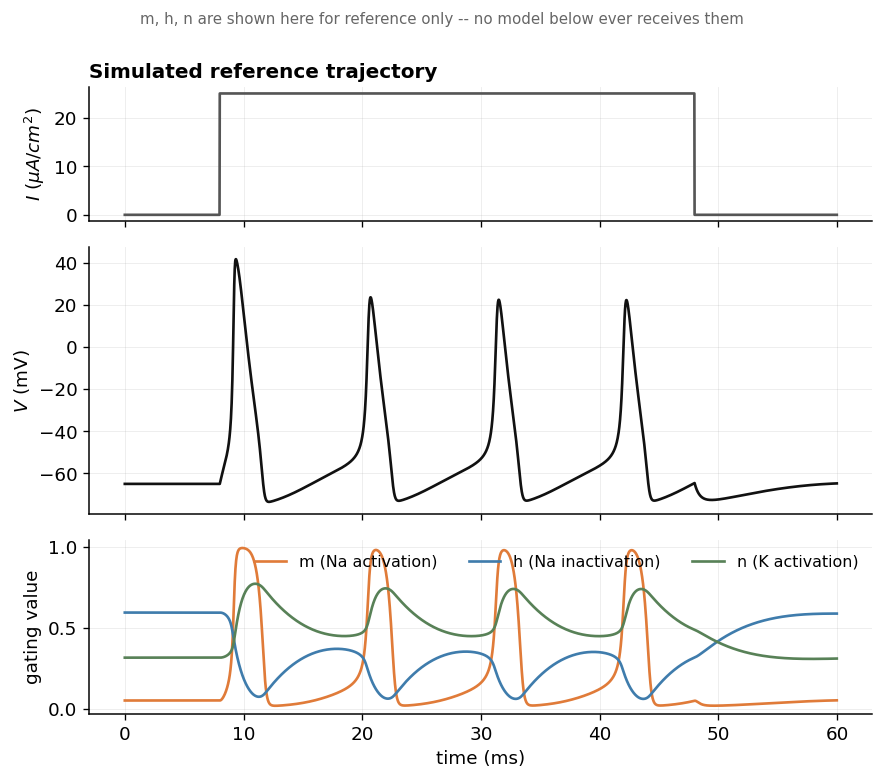

In [ ]:
set_paper_style()

ref_dt = 0.02
n_steps = int(60/ref_dt)
I_ref = step_current(n_steps, ref_dt, amp=25.0, onset_ms=8, dur_ms=40)
fig, states, dVdt = fig_hh_reference({"I": I_ref}, ref_dt)
plt.show()

V, I = states[:, 0], I_ref
n = len(V)
best = None
idxs = np.arange(0, n, 3)
for ii in range(len(idxs)):
    i = idxs[ii]
    for jj in range(ii+1, min(ii+80, len(idxs))):
        j = idxs[jj]
        if abs(i - j) < 200:
            continue
        if abs(V[i]-V[j]) < 1.0 and abs(I[i]-I[j]) < 0.5:
            diff = abs(dVdt[i]-dVdt[j])
            if best is None or diff > best[0]:
                best = (diff, i, j)
_, i, j = best
t = np.arange(n) * ref_dt
ambiguity_summary = pd.DataFrame({
    "point": ["A", "B"],
    "time_ms": [round(i*ref_dt,2), round(j*ref_dt,2)],
    "I": [round(float(I[i]),2), round(float(I[j]),2)],
    "V_mV": [round(float(V[i]),2), round(float(V[j]),2)],
    "dV/dt": [round(float(dVdt[i]),2), round(float(dVdt[j]),2)],
    "m": [round(float(states[i,1]),3), round(float(states[j,1]),3)],
    "h": [round(float(states[i,2]),3), round(float(states[j,2]),3)],
    "n": [round(float(states[i,3]),3), round(float(states[j,3]),3)],
})

### 4.3 Stimulus protocol and data split

To avoid a model simply memorizing one particular current waveform, the
training set spans several different current *shapes*: step pulses at a
range of strengths, ramps, and smoothly-wandering random current (an
Ornstein-Uhlenbeck process - random noise smoothed so it does not jump
instantaneously, closer to naturalistic synaptic input than pure white
noise). The validation set uses the same waveform *families* at different
specific parameter values. The **test set contains two waveform types never
presented during training at all** - a sine-wave current, and a step
current stronger than any seen in training - so that free-running accuracy
is measured under genuine generalization, not interpolation.

In [ ]:
import numpy as np

def make_trial(I, dt, seed_state=None):
    states, dVdt = simulate(I, dt, state0=seed_state)
    return {"I": I.astype(np.float32), "V": states[:,0].astype(np.float32),
            "dVdt": dVdt.astype(np.float32), "dt": dt}

def build_dataset(dt=0.02, seed=0):
    rng = np.random.default_rng(seed)
    train_trials, val_trials, test_trials = [], [], []

    # TRAIN: steps + ramps + OU noise across a range of amplitudes
    step_amps = [2, 4, 6, 8, 10, 12, 15, 18]
    for amp in step_amps:
        dur_ms = 60
        n_steps = int(dur_ms/dt)
        I = step_current(n_steps, dt, amp=amp, onset_ms=8, dur_ms=40)
        train_trials.append(make_trial(I, dt))

    for (a0, a1) in [(0,15), (0,20), (5,-5), (20,0)]:
        dur_ms = 60
        n_steps = int(dur_ms/dt)
        I = ramp_current(n_steps, dt, amp_start=a0, amp_end=a1, onset_ms=8, dur_ms=45)
        train_trials.append(make_trial(I, dt))

    for (sigma, tau) in [(3.0, 2.0), (5.0, 4.0), (2.0, 8.0)]:
        dur_ms = 80
        n_steps = int(dur_ms/dt)
        I = ou_noise_current(n_steps, dt, mean=6.0, sigma=sigma, tau_ms=tau, rng=rng)
        train_trials.append(make_trial(I, dt))

    # A couple of low-amplitude (subthreshold) trials so the network also sees non-spiking dynamics
    for amp in [0.5, 1.5, -2.0]:
        dur_ms = 50
        n_steps = int(dur_ms/dt)
        I = step_current(n_steps, dt, amp=amp, onset_ms=5, dur_ms=35)
        train_trials.append(make_trial(I, dt))

    # VAL: same protocol families, different (interpolated) params
    for amp in [3, 7, 11, 16]:
        dur_ms = 60
        n_steps = int(dur_ms/dt)
        I = step_current(n_steps, dt, amp=amp, onset_ms=8, dur_ms=40)
        val_trials.append(make_trial(I, dt))
    I = ou_noise_current(int(70/dt), dt, mean=6.0, sigma=4.0, tau_ms=3.0, rng=rng)
    val_trials.append(make_trial(I, dt))

    # TEST: two stimulus families NEVER seen in training -> generalization
    # (kept deliberately small: one smooth/periodic waveform, one amplitude
    # extrapolation, so each failure mode is easy to see and reason about)

    # 1) sinusoidal drive - a smoothly-varying waveform shape never seen in training
    n_steps = int(100/dt)
    I = sine_current(n_steps, dt, amp=10.0, freq_hz=30, offset=6.0)
    test_trials.append({"name": "sine_30Hz", **make_trial(I, dt)})

    # 2) step above the max trained amplitude -- tests extrapolation beyond the
    #    current range the network was trained on
    n_steps = int(60/dt)
    I = step_current(n_steps, dt, amp=25.0, onset_ms=8, dur_ms=40)
    test_trials.append({"name": "step_25_extrapolation", **make_trial(I, dt)})

    return train_trials, val_trials, test_trials

def compute_norm_stats(trials):
    all_I = np.concatenate([t["I"] for t in trials])
    all_V = np.concatenate([t["V"] for t in trials])
    all_dVdt = np.concatenate([t["dVdt"] for t in trials])
    stats = {
        "I_mean": all_I.mean(), "I_std": all_I.std() + 1e-8,
        "V_mean": all_V.mean(), "V_std": all_V.std() + 1e-8,
        "dVdt_mean": all_dVdt.mean(), "dVdt_std": all_dVdt.std() + 1e-8,
    }
    return stats

In [2]:
# Configuration

QUICK_TEST = False

DT = 0.02  # ms, simulation / dataset timestep
if QUICK_TEST:
    W = 80
    N_SEEDS = 2
    EPOCHS = dict(mlp=12, tcn=12, gru=5)
else:
    W = 250        # ~5 ms -- spans the fast (Na) and slower (K, Na-inactivation) timescales
    N_SEEDS = 3
    EPOCHS = dict(mlp=50, tcn=50, gru=25)
BATCH = 256
# -------------------------------------------------

train_trials, val_trials, test_trials = build_dataset(dt=DT, seed=1)
if QUICK_TEST:
    train_trials = train_trials[:11]

stats = compute_norm_stats(train_trials)
print(f"training trials: {len(train_trials)}  (total simulated timesteps: "
      f"{sum(len(t['I']) for t in train_trials)})")
print(f"validation trials: {len(val_trials)}")
print(f"held-out test trials: {len(test_trials)}  -> {[t['name'] for t in test_trials]}")

NameError: name 'build_dataset' is not defined

### 4.4 Giving models access to history

Rather than a single instant $(I_t, V_t)$, the "with history" models
receive a short **window** of the last $W$ instants -- like watching the
last few frames of a video instead of one freeze-frame. This is a **delay
embedding**; setting the window length to 1 recovers exactly the
"no history" case, so all three models share one data pipeline, differing
only in how much of it they are given.

In [ ]:
import numpy as np
import torch
from torch.utils.data import Dataset

class WindowedDataset(Dataset):
    """
    Every sample is a window of the last W (I, V) pairs ending at time t,
    with target = the true dV/dt at time t. W=1 gives the memoryless
    (I_t, V_t) -> dVdt_t setup used for the MLP.
    """
    def __init__(self, trials, W, stats):
        self.W = W
        self.stats = stats
        self.samples = []  # (trial_idx, end_idx)
        self.trials = trials
        for ti, tr in enumerate(trials):
            n = len(tr["I"])
            for end in range(W - 1, n):
                self.samples.append((ti, end))

    def __len__(self):
        return len(self.samples)

    def _n(self, x, mean, std): return (x - mean) / std

    def __getitem__(self, idx):
        ti, end = self.samples[idx]
        tr = self.trials[ti]
        start = end - self.W + 1
        I_win = self._n(tr["I"][start:end+1], self.stats["I_mean"], self.stats["I_std"])
        V_win = self._n(tr["V"][start:end+1], self.stats["V_mean"], self.stats["V_std"])
        target = self._n(tr["dVdt"][end], self.stats["dVdt_mean"], self.stats["dVdt_std"])
        x = np.stack([I_win, V_win], axis=-1).astype(np.float32)  # (W, 2)
        return {"x": torch.from_numpy(x), "y": torch.tensor(target, dtype=torch.float32)}

In [ ]:
ds_train = WindowedDataset(train_trials, W=W, stats=stats)
ds_val = WindowedDataset(val_trials, W=W, stats=stats)
dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True)
dl_val = DataLoader(ds_val, batch_size=1024, shuffle=False)
print(f"{len(ds_train)} training windows (each covering {W} simulated steps = {W*DT:.1f} ms)")
print(f"{len(ds_val)} validation windows")

51018 training windows (each covering 250 simulated steps = 5.0 ms)
14255 validation windows


### 4.5 The three models

All three models are given the same *kind* of information at input - either
nothing but the current instant $(I_t, V_t)$, or a window of the last $W$
such pairs - and differ only in how that input is turned into a predicted
$dV/dt$.

**MLP (no history).** A small feedforward neural network - a stack of
linear layers separated by a nonlinear function (`Tanh`) - applied *only*
to the current instant $(I_t, V_t)$. This is the negative control: by
construction, it has no mechanism by which the recent past could influence
its prediction.

**TCN, "Temporal Convolutional Network" (with history).** Rather than
treating every past time-lag as an unrelated input slot, a **convolution**
learns one small filter (a handful of numbers) and *slides it* across every
position in the window, reusing the same weights everywhere - the same
principle used for images, applied here along time. A single convolutional
layer can only see as far back as its filter width; stacking layers with
**dilation** (each layer skips further apart than the last - 1 step, then
2, then 4, and so on) lets the network's **receptive field** (how far back
it can "see") grow quickly without needing a large filter or many layers.
We use a standard causal, dilated design (Bai, Kolter, & Koltun, 2018),
built on the same principle as the classical time-delay neural network
(Waibel et al., 1989): a *causality* constraint (implemented by padding the
input on the left before each convolution) additionally guarantees that a
prediction for time $t$ never has access to information from after $t$.

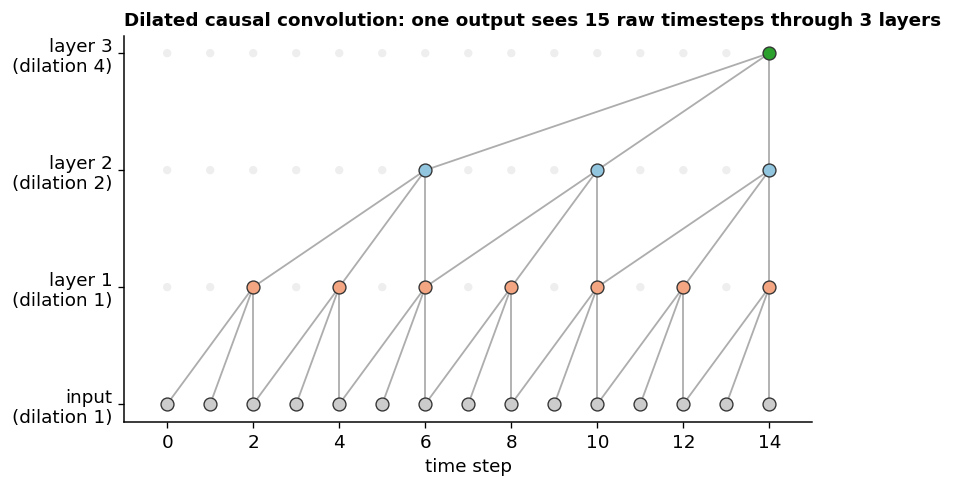

In [ ]:
_ = fig_tcn_receptive_field()
plt.show()

Trace the lines backward from the single highlighted output node at the
top: through 3 layers, using only a 3-number filter at each layer, it
already depends on 15 different raw input timesteps. The number of layers
used for the actual TCN below (`dilations_to_cover`) is chosen automatically
so that its receptive field covers the *entire* window $W$, whatever $W$ is
set to.

**GRU, "Gated Recurrent Unit" (with history).** A **recurrent neural
network** takes a fundamentally different approach: rather than keeping any
window of raw values at all, it keeps a small hidden vector $h_t$ that is
updated at every timestep, $h_t = \\text{update}(h_{t-1}, \\text{input}_t)$,
acting as a continuously-maintained summary of everything seen so far. A GRU
refines this update with two learned gates (values between 0 and 1): an
**update gate**, controlling how much new information to blend in, and a
**reset gate**, controlling how much of the old summary to discard when
computing that new information (Cho et al., 2014). Its memory horizon is not
fixed by a window-length choice the way TCN's is - it is whatever the gates
learn to preserve across time.

Comparing MLP to the other two isolates whether having *any* access to
history helps; comparing TCN to GRU, which are given an *identical* amount
of raw information ($W$ past instants either way), isolates whether the
*mechanism* used to exploit that history - a fixed sliding filter versus a
learned, continuously-updated summary - matters further.

In [ ]:
import torch
import torch.nn as nn


class MemorylessMLP(nn.Module):
    """dV/dt_t = f(I_t, V_t), f a small nonlinear (2-hidden-layer) network.
    No history at all -- the negative control. If the hidden-state ambiguity
    described in the Introduction is real, no amount of width or depth here
    should fix it, because the missing information (recent history) is
    simply not present in the input."""
    def __init__(self, hidden=(64, 64)):
        super().__init__()
        layers = []
        sizes = [2, *hidden, 1]
        for i in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[i], sizes[i+1]))
            if i < len(sizes) - 2:
                layers.append(nn.Tanh())
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        last = x[:, -1, :]
        return self.net(last).squeeze(-1)


class CausalConv1d(nn.Module):
    """A 1D convolution that only looks backward in time: the input is
    padded on the left before convolving, so the output at time t depends
    only on inputs at or before t, never on the future."""
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)

    def forward(self, x):
        x = nn.functional.pad(x, (self.pad, 0))
        return self.conv(x)


def dilations_to_cover(window, kernel_size=3):
    """Smallest set of doubling dilations [1, 2, 4, ...] whose combined
    receptive field covers the full window, for a fixed kernel_size."""
    dilations, receptive_field, d = [], 1, 1
    while receptive_field < window:
        dilations.append(d)
        receptive_field += (kernel_size - 1) * d
        d *= 2
    return dilations, receptive_field


class TCN(nn.Module):
    """A Temporal Convolutional Network: a stack of causal, dilated 1D
    convolutions (Bai, Kolter, & Koltun, 2018) -- the same general lineage
    as the classical time-delay neural network (Waibel et al., 1989). A
    single small filter (kernel_size weights) is reused ('shared') at every
    position in the window, rather than learning a separate weight for every
    time-lag; stacking layers with doubling dilation lets the receptive
    field (how far back the model can 'see') grow quickly without a large
    number of parameters."""
    def __init__(self, W, channels=32, kernel_size=3):
        super().__init__()
        self.dilations, self.receptive_field = dilations_to_cover(W, kernel_size)
        chs = [2] + [channels] * len(self.dilations)
        self.layers = nn.ModuleList([
            CausalConv1d(chs[i], chs[i+1], kernel_size, self.dilations[i])
            for i in range(len(self.dilations))
        ])
        self.act = nn.ReLU()
        self.head = nn.Linear(channels, 1)

    def forward(self, x):
        h = x.transpose(1, 2)              # (B, W, 2) -> (B, 2, W) for Conv1d
        for layer in self.layers:
            h = self.act(layer(h))
        last = h[:, :, -1]                 # features at the most recent timestep
        return self.head(last).squeeze(-1)


class GRURegressor(nn.Module):
    """Processes the (I, V) window through a GRU (a recurrent network with
    learned 'update' and 'reset' gates) and reads dV/dt off the final hidden
    state -- memory as a small, continuously-updated running summary, rather
    than a fixed window of raw values."""
    def __init__(self, hidden_size=32, num_layers=1):
        super().__init__()
        self.gru = nn.GRU(input_size=2, hidden_size=hidden_size,
                           num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, h_n = self.gru(x)
        last = out[:, -1, :]
        return self.head(last).squeeze(-1)

### 4.6 Fitting the models

All three networks are trained by **gradient descent**: repeatedly (1)
computing predictions for a batch of examples, (2) measuring error with
**mean squared error (MSE)** - the average *squared* difference between
predicted and true $dV/dt$ - and (3) using calculus (`loss.backward()`,
**backpropagation**) to compute how each parameter should be nudged to
reduce that error, then applying a small nudge (`optimizer.step()`). One
full pass through the training set is an **epoch**. Every network is
trained **`N_SEEDS` independent times** from different random starting
points (Design, above), with an identical optimizer, learning rate, and
epoch budget across architectures - the only thing that differs between
runs of the same architecture is the random initialization. All variables
are standardized (rescaled to mean 0, standard deviation 1) before training
and converted back to real physical units (mV, mV/ms) whenever a result is
reported.

In [ ]:
def train_neural(model_ctor, epochs, seed, tag):
    torch.manual_seed(seed)
    model = model_ctor().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    hist = []
    t0 = time.time()
    for ep in range(epochs):
        tot, n = 0.0, 0
        for batch in dl_train:
            x, y = batch["x"].to(device), batch["y"].to(device)
            opt.zero_grad()
            pred = model(x)
            loss = nn.functional.mse_loss(pred, y)
            loss.backward()
            opt.step()
            tot += loss.item()*x.shape[0]; n += x.shape[0]
        hist.append(tot/n)
    print(f"  [{tag} seed={seed}] final training loss={hist[-1]:.5f}  ({time.time()-t0:.1f}s)")
    return model.cpu(), hist

print("Training MLP (no history) -- zero memory:")
mlp_models, mlp_hists = [], []
for s in range(N_SEEDS):
    m, h = train_neural(MemorylessMLP, EPOCHS["mlp"], s, "MLP")
    mlp_models.append(m); mlp_hists.append(h)

print("\nTraining TCN (with history) -- sliding-filter memory:")
tcn_models, tcn_hists = [], []
for s in range(N_SEEDS):
    m, h = train_neural(lambda: TCN(W=W), EPOCHS["tcn"], s, "TCN")
    tcn_models.append(m); tcn_hists.append(h)

print("\nTraining GRU (with history) -- learned recurrent memory:")
gru_models, gru_hists = [], []
for s in range(N_SEEDS):
    m, h = train_neural(lambda: GRURegressor(hidden_size=32), EPOCHS["gru"], s, "GRU")
    gru_models.append(m); gru_hists.append(h)

Training MLP (no history) -- zero memory:
  [MLP seed=0] final training loss=0.99984  (81.2s)
  [MLP seed=1] final training loss=0.99940  (86.8s)
  [MLP seed=2] final training loss=0.99878  (82.1s)

Training TCN (with history) -- sliding-filter memory:
  [TCN seed=0] final training loss=0.00154  (140.3s)
  [TCN seed=1] final training loss=0.00110  (140.4s)
  [TCN seed=2] final training loss=0.00154  (140.0s)

Training GRU (with history) -- learned recurrent memory:
  [GRU seed=0] final training loss=0.00846  (53.4s)
  [GRU seed=1] final training loss=0.00412  (54.3s)
  [GRU seed=2] final training loss=0.00143  (55.1s)


### 4.7 Evaluation

Two complementary tests are used, corresponding to the two parts of the
Objective:

**(a) One-step prediction.** Each model is given a *true* window of recent
history (never anything the model generated itself) and asked for the very
next $dV/dt$, evaluated on the held-out validation set. Scored with $R^2$
(percentage of variance explained: 1 = perfect, 0 = no better than always
guessing the average, negative = worse than guessing the average).

**(b) Free-running simulation.** After a short **burn-in** (seeded with true
values, since every model needs *some* starting history), each model is run
entirely on **its own previous predictions** for the rest of the trace - the
only external input still provided is the true stimulus current $I(t)$
itself. This is a materially harder test: in (a), a wrong prediction has no
consequence for the next input; in (b), it does, because the model's own
error becomes part of what it sees next. Scored with root-mean-squared
error (**RMSE**, in mV) against the true trajectory, on the two held-out
test stimuli.

As a simple, purely descriptive check, we also count the number of action
potentials ("spikes") each model produces during free-running simulation,
using a standard fixed-threshold crossing rule (voltage crossing 0 mV,
rising), and compare this count to the true number - with no scoring or
statistical weight attached, since spike-detection thresholds are a
convention, not a ground truth.

In [ ]:
import numpy as np
import torch

def _n(x, mean, std): return (x - mean) / std
def _dn(x, mean, std): return x * std + mean

# Safety clamp so a poorly-trained / diverging model can't send the plots to
# +-infinity -- physiologically V should never leave this range.
V_CLIP = (-150.0, 100.0)


@torch.no_grad()
def rollout_windowed(model, trial, stats, dt, W):
    """Free-running rollout shared by MLP (W=1), NARX (W>1), and TCN (W>1).
    The first W steps are 'burn-in' (seeded with the true trajectory, since
    the model needs *some* history to start from). After that, I is always
    the true, known stimulus, but V is entirely generated by the model
    feeding on its own previous outputs."""
    I = trial["I"]; V_true = trial["V"]; n = len(I)
    V_pred = np.zeros(n, dtype=np.float32)
    V_pred[:W] = V_true[:W]
    I_n = _n(I, stats["I_mean"], stats["I_std"])
    for t in range(W, n):
        V_hist_n = _n(V_pred[t-W:t], stats["V_mean"], stats["V_std"])
        I_hist_n = I_n[t-W:t]
        x = np.stack([I_hist_n, V_hist_n], axis=-1)[None, ...]
        x = torch.from_numpy(x.astype(np.float32))
        dvdt_n = model(x).numpy()[0]
        dvdt = _dn(dvdt_n, stats["dVdt_mean"], stats["dVdt_std"])
        V_pred[t] = np.clip(V_pred[t-1] + dt * dvdt, *V_CLIP)
    return V_pred


@torch.no_grad()
def rollout_gru(model, trial, stats, dt, W):
    """Free-running rollout for the GRU: burn in the hidden state on the
    first W true samples, then step one timestep at a time, carrying the
    hidden state forward and feeding the model's own generated V back in."""
    I = trial["I"]; V_true = trial["V"]; n = len(I)
    V_pred = np.zeros(n, dtype=np.float32)
    V_pred[:W] = V_true[:W]
    I_n = _n(I, stats["I_mean"], stats["I_std"])
    V_n_burn = _n(V_pred[:W], stats["V_mean"], stats["V_std"])
    x_burn = np.stack([I_n[:W], V_n_burn], axis=-1)[None, ...]
    x_burn = torch.from_numpy(x_burn.astype(np.float32))
    out, h = model.gru(x_burn)
    for t in range(W, n):
        V_cur_n = _n(V_pred[t-1], stats["V_mean"], stats["V_std"])
        x_t = torch.tensor([[[I_n[t-1], V_cur_n]]], dtype=torch.float32)
        out, h = model.gru(x_t, h)
        dvdt_n = model.head(out[:, -1, :]).numpy()[0, 0]
        dvdt = _dn(dvdt_n, stats["dVdt_mean"], stats["dVdt_std"])
        V_pred[t] = np.clip(V_pred[t-1] + dt * dvdt, *V_CLIP)
    return V_pred


def count_spikes(V, thresh=0.0):
    """Simple upward threshold-crossing spike counter (V crossing 0 mV going up)."""
    above = V >= thresh
    return int(np.sum((~above[:-1]) & (above[1:])))

## 5. Results

Results are reported here without interpretation; each numbered result
(R0-R5) is interpreted in the correspondingly numbered subsection of
Section 6.

### R0. The hidden-state ambiguity, confirmed directly in the simulated data

point  time_ms    I   V_mV  dV/dt     m     h     n
    A    18.42 25.0 -56.83   3.50 0.118 0.370 0.451
    B    22.44 25.0 -57.50 -58.13 0.507 0.069 0.731


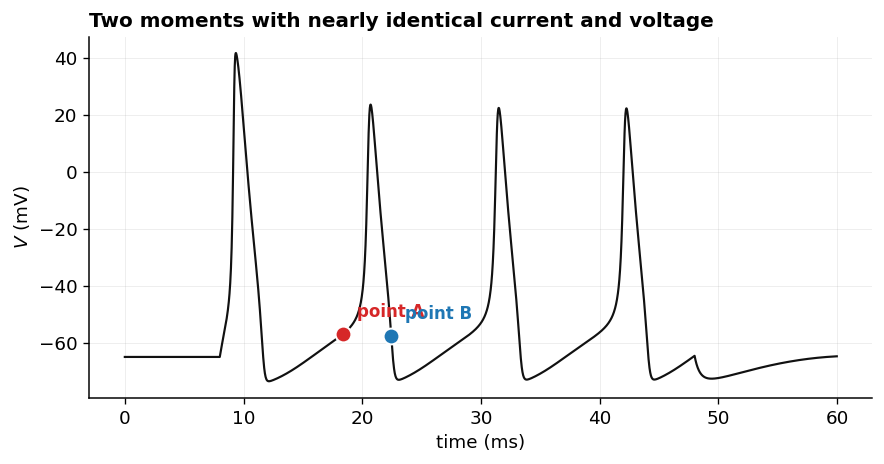

In [ ]:
print(ambiguity_summary.to_string(index=False))
fig_ambiguity_proof(t, V, I, dVdt, states, i, j)
plt.show()

### R1. Training progress

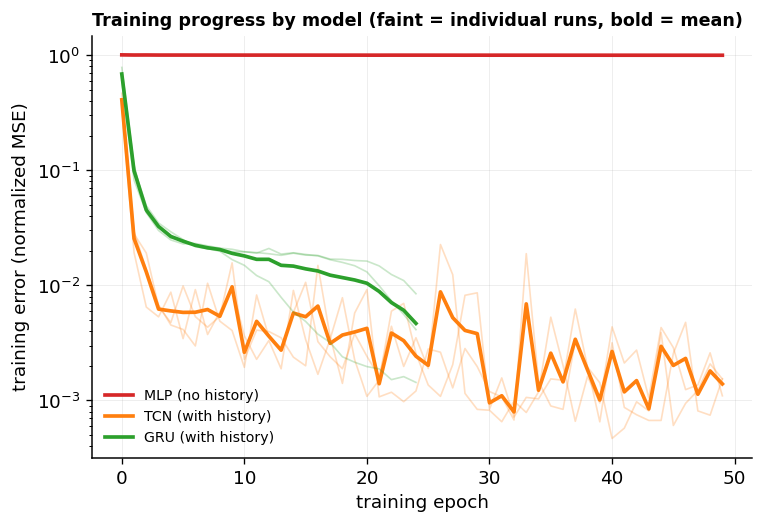

In [ ]:
_ = fig_training_curves({"MLP (no history)": mlp_hists, "TCN (with history)": tcn_hists,
                          "GRU (with history)": gru_hists})
plt.show()

### R2. One-step prediction accuracy (held-out validation data)

             model  mean_R2   sd_R2  n_fits
  MLP (no history)  0.00178 0.00044       3
TCN (with history)  0.99830 0.00128       3
GRU (with history)  0.99744 0.00189       3


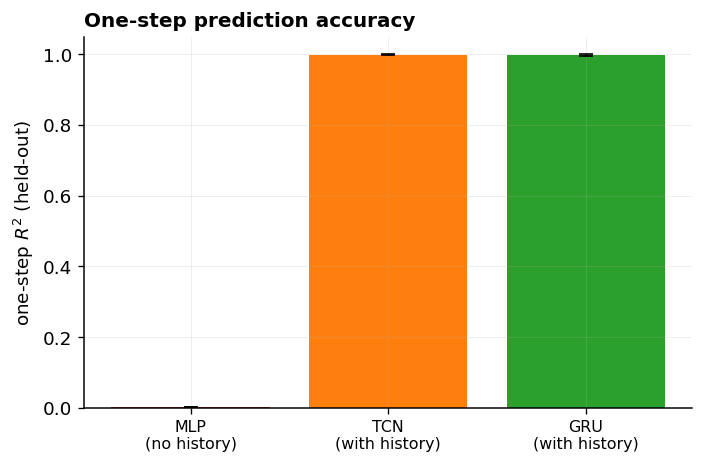

In [ ]:
def r2_score(pred, true):
    return 1 - np.sum((pred-true)**2)/np.sum((true-true.mean())**2)

y_val = np.concatenate([batch["y"].numpy() for batch in dl_val])

mlp_r2s, tcn_r2s, gru_r2s = [], [], []
with torch.no_grad():
    for m in mlp_models:
        preds = np.concatenate([m(batch["x"]).numpy() for batch in dl_val])
        mlp_r2s.append(r2_score(preds, y_val))
    for m in tcn_models:
        preds = np.concatenate([m(batch["x"]).numpy() for batch in dl_val])
        tcn_r2s.append(r2_score(preds, y_val))
    for m in gru_models:
        preds = np.concatenate([m(batch["x"]).numpy() for batch in dl_val])
        gru_r2s.append(r2_score(preds, y_val))

r2_table = pd.DataFrame({
    "model": ["MLP (no history)", "TCN (with history)", "GRU (with history)"],
    "mean_R2": [float(np.mean(mlp_r2s)), float(np.mean(tcn_r2s)), float(np.mean(gru_r2s))],
    "sd_R2": [float(np.std(mlp_r2s)), float(np.std(tcn_r2s)), float(np.std(gru_r2s))],
    "n_fits": [N_SEEDS, N_SEEDS, N_SEEDS],
})
print(r2_table.round(5).to_string(index=False))

r2_vals = {
    "MLP (no history)": (float(np.mean(mlp_r2s)), float(np.std(mlp_r2s))),
    "TCN (with history)": (float(np.mean(tcn_r2s)), float(np.std(tcn_r2s))),
    "GRU (with history)": (float(np.mean(gru_r2s)), float(np.std(gru_r2s))),
}
_ = fig_bar_with_error(r2_vals, "one-step $R^2$ (held-out)", "One-step prediction accuracy")
plt.show()

### R3. Free-running simulation accuracy (held-out generalization stimuli)

             model  mean_RMSE_mV  sd_RMSE_mV  n_values
  MLP (no history)        27.823       5.165         6
TCN (with history)        42.093      26.820         6
GRU (with history)        26.669       5.422         6


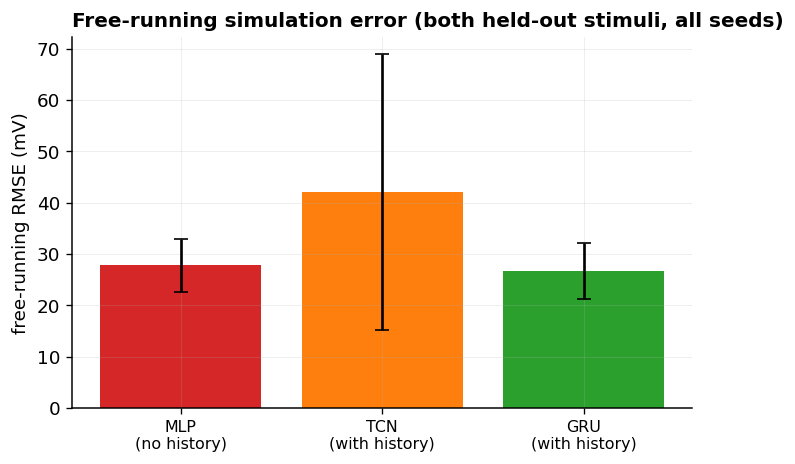

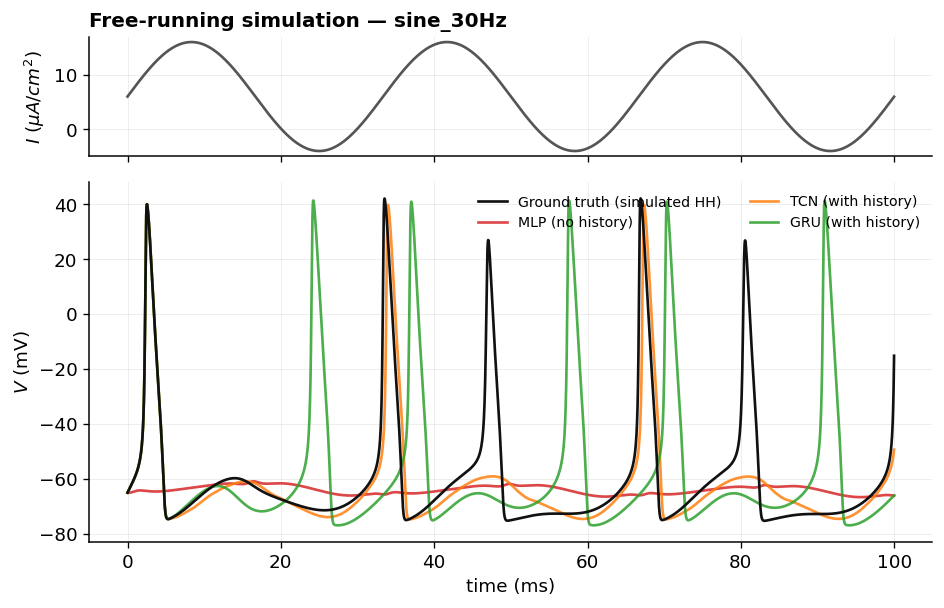

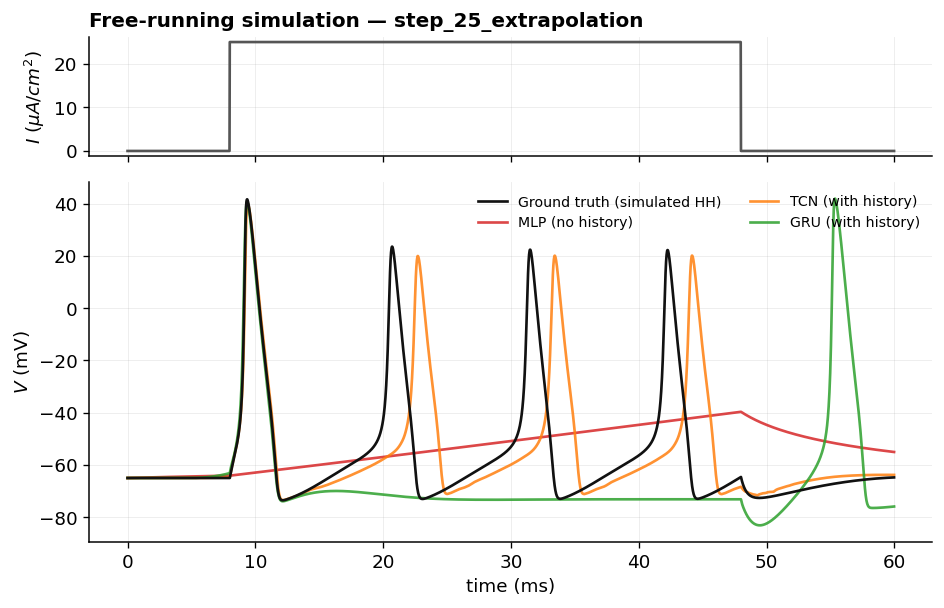

In [ ]:
rollout_store = {}
rmse_values = {name: [] for name in ["MLP (no history)", "TCN (with history)", "GRU (with history)"]}

for tr_full in test_trials:
    tr = dict(tr_full)
    if QUICK_TEST:
        tr["I"]=tr["I"][:2000]; tr["V"]=tr["V"][:2000]; tr["dVdt"]=tr["dVdt"][:2000]
    t_trial = np.arange(len(tr["I"])) * DT

    # representative single run (seed 0) of each architecture, for the trace plots
    Vp_mlp = rollout_windowed(mlp_models[0], tr, stats, DT, W=1)
    Vp_tcn = rollout_windowed(tcn_models[0], tr, stats, DT, W=W)
    Vp_gru = rollout_gru(gru_models[0], tr, stats, DT, W=W)

    rollouts = {"MLP (no history)": Vp_mlp, "TCN (with history)": Vp_tcn, "GRU (with history)": Vp_gru}
    rollout_store[tr["name"]] = (t_trial, tr, rollouts)

    # for the *quantitative* summary, average over ALL seeds, not just the plotted one
    for m in mlp_models:
        v = rollout_windowed(m, tr, stats, DT, W=1)
        rmse_values["MLP (no history)"].append(np.sqrt(np.mean((v-tr["V"])**2)))
    for m in tcn_models:
        v = rollout_windowed(m, tr, stats, DT, W=W)
        rmse_values["TCN (with history)"].append(np.sqrt(np.mean((v-tr["V"])**2)))
    for m in gru_models:
        v = rollout_gru(m, tr, stats, DT, W=W)
        rmse_values["GRU (with history)"].append(np.sqrt(np.mean((v-tr["V"])**2)))

rmse_table = pd.DataFrame({
    "model": list(rmse_values.keys()),
    "mean_RMSE_mV": [float(np.mean(v)) for v in rmse_values.values()],
    "sd_RMSE_mV": [float(np.std(v)) if len(v) > 2 else np.nan for v in rmse_values.values()],
    "n_values": [len(v) for v in rmse_values.values()],
})
print(rmse_table.round(3).to_string(index=False))

rmse_vals = {k: (float(np.mean(v)), float(np.std(v)) if len(v) > 2 else None)
             for k, v in rmse_values.items()}
_ = fig_bar_with_error(rmse_vals, "free-running RMSE (mV)",
                        "Free-running simulation error (both held-out stimuli, all seeds)")
plt.show()

for name, (t_trial, tr, rollouts) in rollout_store.items():
    fig_rollout_traces(t_trial, tr["V"], rollouts, name, I=tr["I"])
    plt.show()

### R4. Voltage vs. rate-of-change trajectory (does the model retrace the true loop?)

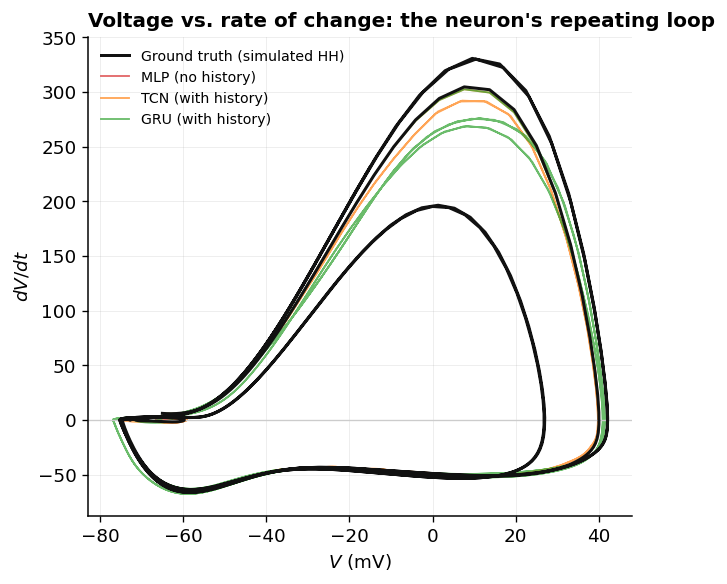

In [ ]:
first_name = list(rollout_store.keys())[0]
t0v, tr0, rollouts0 = rollout_store[first_name]
deriv0 = {k: (v, np.gradient(v, DT)) for k, v in rollouts0.items()}
_ = fig_phase_portrait(tr0["V"], tr0["dVdt"], deriv0)
plt.show()

### R5. Spike counts (descriptive)

In [ ]:
spike_rows = []
for name, (t_trial, tr, rollouts) in rollout_store.items():
    row = {"stimulus": name, "true_spikes": count_spikes(tr["V"])}
    for k, v in rollouts.items():
        row[k] = count_spikes(v)
    spike_rows.append(row)
spike_table = pd.DataFrame(spike_rows)
print(spike_table.to_string(index=False))

             stimulus  true_spikes  MLP (no history)  TCN (with history)  GRU (with history)
            sine_30Hz            5                 0                   3                   6
step_25_extrapolation            4                 0                   4                   2


## 6. Interpretation

Each subsection below interprets the correspondingly numbered result above.
Because exact figures depend on the `QUICK_TEST` setting, seeds, and
hardware, the statements below describe the **pattern** to check your own
printed output against, rather than asserting fixed numbers.

**I0 (ambiguity).** If the table above shows two points with essentially
identical $I$ and $V$ but a large difference in $dV/dt$ - accompanied by a
correspondingly large difference in $m, h, n$ - this directly confirms, in
our own simulated data, that $dV/dt$ is not fully determined by $(I,V)$
alone. This is not a property of any model; it is a property of the
simulated system itself, and it is the premise the rest of the comparison
tests.

**I1 (training progress).** A descending curve indicates the model found
useful patterns in the training data. A curve that stays flat near the
starting loss (watch for this with "MLP, no history") indicates the model
has essentially nothing left to learn from -- consistent with I0: if the
needed information genuinely is not present in $(I_t, V_t)$, no amount of
additional training should move that curve. The shaded spread between the
three individual runs of each architecture indicates how sensitive that
architecture's training is to its random starting point - a wide spread
is itself informative, and is exactly what repeating each fit `N_SEEDS`
times is designed to reveal.

**I2 (one-step accuracy).** Compare the "no history" bar to the two "with
history" bars first. If MLP sits near zero while TCN and GRU both sit much
higher, this indicates the limiting factor was **missing information**
(recent history), not **insufficient model flexibility** - all three
models are nonlinear networks of comparable size, so this contrast is not
explained by one model simply being "smarter" than another. Next compare
TCN to GRU directly: a small remaining gap here would indicate that, once
history is available at all, the *mechanism* used to access it (a fixed
sliding filter vs. a learned recurrent summary) matters comparatively less
for this one-step task than having history in the first place.

**I3 (free-running accuracy).** This is the more demanding test. A model
that scored well in R2 but shows a *large* RMSE here - visibly diverging
from the true trace in its trajectory plot - demonstrates that one-step
accuracy is **not sufficient** for stable free-running behavior: once a
model's own small errors start feeding back into its next input, nothing in
ordinary training (which only ever shows a model *true* windows) corrects
that drift. This effect, sometimes called **exposure bias**, is a property
of *how a model is trained relative to how it is used*, not a defect
specific to any one architecture -- but different architectures can be more
or less exposed to it. If TCN degrades more sharply than GRU between R2 and
R3, that would point to the GRU's bounded, gated hidden-state update as a
plausible source of extra robustness, over and above a fixed convolutional
window - since a gate can learn to partially discount an input it "trusts"
less, while a convolution always weights its window the same fixed way
regardless of how that window was generated. The reverse pattern can also
occur, particularly with few training epochs: if GRU underperforms TCN
here, check first whether its training curve in R1 had actually flattened
out by the final epoch - if not, this result reflects under-training
rather than a genuine architectural disadvantage, and should not be
over-interpreted until `EPOCHS["gru"]` is increased.

**I4 (phase portrait).** A model whose trace forms a loop close to the true
one has captured more than a locally-accurate slope - it has reproduced the
qualitative repeating structure of the spike itself. A model whose trace
spirals away, collapses to a point, or fails to close indicates that,
whatever its one-step accuracy, it has not captured the true dynamics well
enough to sustain them on its own.

**I5 (spike counts).** A model producing a similar number of spikes to the
true count is a weak but intuitive sanity check, consistent with (not
proof of) realistic dynamics; a model producing far too many, far too few,
or zero spikes has clearly failed to reproduce the neuron's basic firing
behavior, regardless of its other scores.

## 7. Discussion

Taken together, the expected pattern across R0-R5 supports a specific,
narrow claim: in this simulated system, the obstacle to predicting $dV/dt$
from $(I, V)$ alone is a **missing-information problem** (the hidden gating
state), not something a bigger or more sophisticated *no-history* model
could fix -- and once that missing information is restored, in the form of
a short window of recent history, the specific mechanism used to exploit it
(sliding convolutional filter vs. learned recurrent summary) matters
comparatively less for one-step accuracy than having history at all, though
it can matter more once a model has to run free of correction. This is
consistent with, and gives a controlled, minimal illustration of, the
general premise behind both the classical system-identification literature
and the modern neural-network literature reviewed in the Introduction:
models given some access to a system's recent history can approximate
hidden-state-dependent dynamics without ever being told what that hidden
state *is*.

**Limitations.** This is a simulation study on a single, fixed set of HH
parameters (the classic squid-axon values) -- the pattern of results is not
guaranteed to hold for other neuron types, other parameter regimes, or real
recorded data, which carries measurement noise this simulation does not.
Only two held-out stimulus types were tested; broader generalization claims
would need a wider stimulus set. The design compares three *nonlinear*
architectures that differ in their access to and use of history; it does
not include a linear model, so it cannot separately establish whether
nonlinearity itself was necessary for the "with history" models' success,
only that some nonlinear architecture with history outperforms one without
-- a natural, straightforward extension for anyone wanting to isolate that
factor as well. Model comparison used **three** independent training runs
per architecture -- enough to check the pattern is not a fluke of one
random initialization, but too few for formal statistical significance
testing, which is why we report descriptive means and standard deviations
rather than $p$-values. The window length $W$ was chosen in advance based
on the known timescales of the slower gating variables and given identically
to TCN and GRU, rather than tuned separately to maximize either model's
reported performance. The "ground truth" itself is a numerical (RK4)
approximation to the HH equations, though at a far smaller step size than
any model here is asked to reproduce. Free-running evaluation used a
true-value burn-in period before releasing each model to run on its own --
a standard, but not the only possible, evaluation convention. Finally,
spike counts are reported descriptively only, using an arbitrary (if
standard) fixed-threshold convention, and carry no statistical weight in
the comparison.

## 8. Implication

This notebook is an illustrative, self-contained simulation exercise, not a
recommendation for modeling real neural data and not a claim about how real
biological neurons should be modeled. Its scope is limited to what it
directly shows: within one simulated, fully known system, giving a model
access to a short window of recent history closes most of the gap between
"cannot predict $dV/dt$ at all" and "predicts it very well," and this holds
across two structurally different ways of using that history (convolutional
and recurrent). Whether the more sophisticated of the two is worth its
additional complexity depends on the downstream task -- in particular, on
whether that task requires the model to run stably on its own (Result R3)
rather than just predict one step ahead (Result R2), a distinction that
matters more than it might first appear and is easy to overlook if only
one-step accuracy is reported.

## 9. Conclusion

Using a fully known simulated neuron, we confirmed directly that a
neuron's instantaneous rate of voltage change is not determined by its
current and voltage alone, then showed that this obstacle is overcome by
giving a model access to a short window of recent history, largely
regardless of which of two very different mechanisms (a sliding
convolutional filter or a learned recurrent summary) is used to exploit
that history - while the more sophisticated, recurrent form of memory
showed its main advantage not in one-step prediction, but in the harder
test of sustaining an accurate trajectory when run on its own.

### References

- Hodgkin, A. L., & Huxley, A. F. (1952). A quantitative description of
  membrane current and its application to conduction and excitation in
  nerve. *The Journal of Physiology*, 117(4), 500-544. (Nobel Prize in
  Physiology or Medicine, 1963.)
- Marmarelis, P. Z., & Marmarelis, V. Z. (1978). *Analysis of Physiological
  Systems: The White-Noise Approach.* Plenum Press.
- Waibel, A., Hanazawa, T., Hinton, G., Shikano, K., & Lang, K. J. (1989).
  Phoneme recognition using time-delay neural networks. *IEEE Transactions
  on Acoustics, Speech, and Signal Processing*, 37(3), 328-339.
- Cho, K., van Merrienboer, B., Gulcehre, C., Bahdanau, D., Bougares, F.,
  Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using
  RNN encoder-decoder for statistical machine translation. *Proceedings of
  EMNLP 2014*. arXiv:1406.1078.
- Bai, S., Kolter, J. Z., & Koltun, V. (2018). An empirical evaluation of
  generic convolutional and recurrent networks for sequence modeling.
  arXiv:1803.01271.
- Kuptsov, P. V., Stankevich, N. V., & Bagautdinova, E. R. (2022).
  Discovering dynamical features of Hodgkin-Huxley-type model of
  physiological neuron using artificial neural network. arXiv:2203.14138.
- Kainth, K. S., Joshi, P. D., Dandekar, R. A., Dandekar, R., & Panat, S.
  (2025). Physics-informed neural ODEs with scale-aware residuals for
  learning stiff biophysical dynamics. *Mathematics and Scientific Machine
  Learning (MSML) Conference 2025*. arXiv:2511.11734.
- Beck, J., et al. (2026). Learning hybrid biophysical neuron models with
  neural ODEs. arXiv:2606.16693.

## Pre-run

In [ ]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

# ================= 1. GROUND TRUTH: Hodgkin–Huxley =================
C, gNa, gK, gL = 1., 120., 36., .3
ENa, EK, EL   = 50., -77., -54.4
dt = 0.01

def rates(V):
    x = V+40; am = .1*x/(1-np.exp(-x/10)) if abs(x)>1e-9 else 1.
    bm = 4*np.exp(-(V+65)/18)
    ah = .07*np.exp(-(V+65)/20); bh = 1/(1+np.exp(-(V+35)/10))
    y = V+55;  an = .01*y/(1-np.exp(-y/10)) if abs(y)>1e-9 else .1
    bn = .125*np.exp(-(V+65)/80)
    return am,bm,ah,bh,an,bn

def dstate(s,I):
    V,m,h,n = s; am,bm,ah,bh,an,bn = rates(V)
    return np.array([(I - gNa*m**3*h*(V-ENa) - gK*n**4*(V-EK) - gL*(V-EL))/C,
                     am*(1-m)-bm*m, ah*(1-h)-bh*h, an*(1-n)-bn*n])

def simulate(I_input):
    N=len(I_input); s=np.array([-65., .05, .6, .32])
    V=np.zeros(N); dV=np.zeros(N); G=np.zeros((N,3))   # G = (m,h,n)
    for k in range(N):
        V[k]=s[0]; G[k]=s[1:]; dV[k]=dstate(s,I_input[k])[0]
        k1=dstate(s,I_input[k]); k2=dstate(s+dt/2*k1,I_input[k])
        k3=dstate(s+dt/2*k2,I_input[k]); k4=dstate(s+dt*k3,I_input[k])
        s = s + dt/6*(k1+2*k2+2*k3+k4)
    return I_input, V, dV, G

# ================= 2. STIMULI & DATA =================
T, N = 300., 30000
t = np.arange(N)*dt; on = (t>50)&(t<250)

def stim(kind, amp):
    I = np.zeros(N)
    if kind=='step': I[on]=amp
    elif kind=='ramp': I[on]=amp*(t[on]-50)/200
    elif kind=='sine': I[on]=amp*np.sin(2*np.pi*(t[on]-50)/100)
    return I

train_specs = [('step',5),('step',15),('ramp',10),('ramp',20)]
val_specs   = [('step',10),('ramp',15)]
test_specs  = [('sine',10),('step',25)]        # sine & 25 µA/cm²: unseen

build = lambda specs: [simulate(stim(k,a)) for k,a in specs]
train, val, test = build(train_specs), build(val_specs), build(test_specs)

stack = lambda i: np.concatenate([tr[i] for tr in train])
mu_I, sd_I = stack(0).mean(), stack(0).std()
mu_V, sd_V = stack(1).mean(), stack(1).std()
mu_d, sd_d = stack(2).mean(), stack(2).std()

W, STRIDE = 250, 10                             # 2.5 ms window

def windows(trials):
    X, Y, G = [], [], []
    for I,V,dV,g in trials:
        feat = np.stack([(I-mu_I)/sd_I, (V-mu_V)/sd_V], 1).astype(np.float32)
        y     = ((dV-mu_d)/sd_d).astype(np.float32)
        for k in range(W-1, len(y), STRIDE):
            X.append(feat[k-W+1:k+1]); Y.append(y[k]); G.append(g[k])
    return np.array(X), np.array(Y), np.array(G)

Xtr,Ytr,Gtr = windows(train); Xva,Yva,_ = windows(val); Xte,Yte,Gte = windows(test)

# ================= 3. MODELS (shared head; only memory varies) =================
class Head(nn.Module):                          # identical decoder for all three
    def __init__(s, d):
        super().__init__()
        s.fc1, s.fc2, s.out = nn.Linear(d,64), nn.Linear(64,64), nn.Linear(64,1)
    def forward(s, x):
        z = torch.tanh(s.fc1(x)); z = torch.tanh(s.fc2(z))
        return s.out(z).squeeze(-1), z          # (dV/dt, hidden)

class MLP(nn.Module):                           # memory = one instant
    def __init__(s): super().__init__(); s.head = Head(2)
    def forward(s,x): return s.head(x[:,-1,:])

class TCN(nn.Module):                           # memory = fixed window
    def __init__(s, ch=32, dils=(1,2,4,8,16,32)):
        super().__init__()
        chans = [2]+[ch]*len(dils)
        s.convs = nn.ModuleList(nn.Conv1d(chans[i], chans[i+1], 3, dilation=d, padding=2*d)
                                for i,d in enumerate(dils))
        s.head = Head(ch)
    def forward(s,x):
        h = x.transpose(1,2)
        for c in s.convs: h = torch.relu(c(h))[:,:,:W]   # crop → causal
        return s.head(h[:,:,-1])

class GRU(nn.Module):                           # memory = learned, unbounded
    def __init__(s, h=32):
        super().__init__()
        s.rnn = nn.GRU(2, h, batch_first=True); s.head = Head(h)
    def forward(s,x):
        h,_ = s.rnn(x); return s.head(h[:,-1,:])

# ================= 4. TRAIN =================
def train(model, epochs=30):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3); loss = nn.MSELoss()
    Xt,Yt = torch.tensor(Xtr), torch.tensor(Ytr)
    Xv,Yv = torch.tensor(Xva), torch.tensor(Yva)
    best=(1e9,None)
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(Xt))
        for i in range(0,len(Xt),128):
            idx = perm[i:i+128]; opt.zero_grad()
            loss(model(Xt[idx])[0], Yt[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad(): vl = loss(model(Xv)[0], Yv).item()
        if vl < best[0]: best = (vl, {k:v.clone() for k,v in model.state_dict().items()})
    model.load_state_dict(best[1]); return model

# ================= 5. EVALUATE (three metrics → three questions) =================
def free_run(model, I_input):                         # Q1: replicate dynamics?
    V = np.full(N, -65.)
    for k in range(1,N):
        lo = max(0, k-W+1); iw = I_input[lo:k+1]; vw = V[lo:k+1]
        if len(iw)<W:
            pad = W-len(iw); iw = np.r_[np.full(pad,I_input[0]), iw]; vw = np.r_[np.full(pad,-65.), vw]
        x = np.stack([(iw-mu_I)/sd_I, (vw-mu_V)/sd_V], 1)[None].astype(np.float32)
        with torch.no_grad(): d,_ = model(torch.tensor(x))
        V[k] = V[k-1] + dt*(d.item()*sd_d + mu_d)
    return V

def ridge_r2(A, Y, A_test=None):                # linear probe
    A_for_fit = np.hstack([A, np.ones((len(A),1))])
    Wls,*_ = np.linalg.lstsq(A_for_fit, Y, rcond=None)

    A_for_prediction = A_for_fit # Default to A_for_fit if A_test is None
    if A_test is not None:
        A_for_prediction = np.hstack([A_test, np.ones((len(A_test),1))])

    P = A_for_prediction @ Wls
    return 1 - ((Y-P)**2).sum(0)/((Y-Y.mean(0))**2).sum(0)

def evaluate(model, X, Y, G, trials):
    model.eval()
    with torch.no_grad(): d,_ = model(torch.tensor(X))
    r2_1step = 1 - ((Y - d.numpy())**2).sum()/((Y - Y.mean())**2).sum()

    rmses, spikes = [], []
    for I_val,V_val,_,_ in trials:
        Vh = free_run(model, I_val)
        rmses.append(np.sqrt(np.mean((Vh-V_val)**2)))
        spikes.append((int(((Vh[:-1]<0)&(Vh[1:]>=0)).sum()),
                       int(((V_val[:-1]<0)&(V_val[1:]>=0)).sum())))

    # Q2: does the hidden state linearly encode (m,h,n)?
    Zs = []
    with torch.no_grad():
        for i in range(0,len(X),512):
            _,z = model(torch.tensor(X[i:i+512])); Zs.append(z.numpy())
    Z = np.concatenate(Zs)
    gating_r2  = ridge_r2(Z, G)                          # from hidden
    V_baseline = X[:,-1,1:2]                             # normalized V alone
    base_r2    = ridge_r2(V_baseline, G)                 # trivial baseline

    return r2_1step, rmses, spikes, gating_r2, base_r2

# ================= 6. RUN =================
def run_seed(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    return {name: evaluate(train(m()), Xte, Yte, Gte, test)
            for name, m in [('MLP',MLP), ('TCN',TCN), ('GRU',GRU)]}

runs = [run_seed(s) for s in (0,1,2)]

# -------- Report --------
print(f"{'model':6s} {'1-step R²':>10s} {'free-run RMSE':>14s} {'spikes (pred/true)':>20s} "
      f"{'gating R² (m,h,n)':>22s} {'V-only baseline':>18s}")
for name in ('MLP','TCN','GRU'):
    r2   = np.mean([r[name][0] for r in runs])
    rmse = np.mean([np.mean(r[name][1]) for r in runs])
    sp   = np.mean([np.array(r[name][2]) for r in runs], axis=0)
    gR2  = np.mean([r[name][3] for r in runs], axis=0)
    bR2  = np.mean([r[name][4] for r in runs], axis=0)
    print(f"{name:6s} {r2:>10.3f} {rmse:>14.1f} {str(sp.astype(int).tolist()):>20s} "
          f"{str(np.round(gR2,2)):>22s} {str(np.round(bR2,2)):>18s}")

# -------- Plot: ground truth vs free-run (seed 0) --------
models_s0 = {n: train(m()) for n,m in [('MLP',MLP),('TCN',TCN),('GRU',GRU)]}
fig, ax = plt.subplots(1,2, figsize=(10,3), sharey=True)
for i,(I_plot,V_plot,_,_) in enumerate(test):
    ax[i].plot(t, V_plot, 'k', lw=1, label='HH')
    for name, c in [('MLP','tab:red'),('TCN','tab:green'),('GRU','tab:blue')]:
        ax[i].plot(t, free_run(models_s0[name], I_plot), c, lw=1, label=name)
    ax[i].set_title(f"test {test_specs[i][0]} {test_specs[i][1]}"); ax[i].set_xlabel("t (ms)")
ax[0].set_ylabel("V (mV)"); ax[0].legend()
plt.tight_layout(); plt.show()

model   1-step R²  free-run RMSE   spikes (pred/true)      gating R² (m,h,n)    V-only baseline
MLP        -0.000           24.5    [[0, 6], [0, 19]]       [0.9  0.94 0.89]   [0.81 0.26 0.27]
TCN         0.949          361.4    [[5, 6], [2, 19]]       [1.   0.94 0.94]   [0.81 0.26 0.27]
GRU         0.958           24.0    [[6, 6], [0, 19]]       [1.   0.98 0.98]   [0.81 0.26 0.27]
